# Experimento 4 — Independência entre Rodadas
**Máquina Estatística — Probabilidade e Estatística I (IFES Serra - 2026/2)**  
**Equipe:** João Victor Santos Araujo & João Victor Nascimento Ribeiro  
**Professor:** Fidelis Zanetti de Castro  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joaovictorsaraujo/maquina-estatistica/blob/master/notebooks/04_independencia.ipynb)

---
### Descrição do Experimento
Análise de 9.999 pares consecutivos, cálculo de probabilidades condicionais e refutação empírica da falácia do jogador.


In [1]:
# Configuração de ambiente para Google Colab e ambiente local
import sys
from pathlib import Path

# Se executando no Google Colab, clona o repositório para obter tabelas e resultados
if 'google.colab' in sys.modules:
    if not Path('resultados/tabelas').is_dir():
        !git clone https://github.com/joaovictorsaraujo/maquina-estatistica.git
        %cd maquina-estatistica

try:
    from IPython.display import display
except ImportError:
    display = print

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Funciona se o notebook for aberto a partir da raiz do repositório
# ou da pasta notebooks/, inclusive no VS Code/WSL.
local_atual = Path.cwd().resolve()
raiz = next(
    (
        diretorio for diretorio in (local_atual, *local_atual.parents)
        if (diretorio / "resultados" / "tabelas" / "e4_condicional.csv").is_file()
    ),
    None,
)

if raiz is None:
    raise FileNotFoundError(
        "Não encontrei resultados/tabelas/e4_condicional.csv. "
        "Abra o notebook dentro do repositório maquina-estatistica."
    )

arquivo_e4 = raiz / "resultados" / "tabelas" / "e4_condicional.csv"
pasta_graficos = raiz / "resultados" / "graficos" / "notebooks"
pasta_graficos.mkdir(parents=True, exist_ok=True)

print("Arquivo de entrada:", arquivo_e4)
print("Gráficos serão salvos em:", pasta_graficos)

Arquivo de entrada: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\tabelas\e4_condicional.csv
Gráficos serão salvos em: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\graficos\notebooks


In [2]:
df_original = pd.read_csv(arquivo_e4)

colunas_exigidas = {
    "condicao_anterior", "total_pares", "premios_seguintes",
    "proporcao_observada", "referencia_teorica", "status",
}
assert colunas_exigidas.issubset(df_original.columns), (
    f"Colunas ausentes: {colunas_exigidas - set(df_original.columns)}"
)

print("Tabela original do Experimento 4:")
display(df_original)

Tabela original do Experimento 4:


,condicao_anterior,total_pares,premios_seguintes,proporcao_observada,referencia_teorica,status
0,Após rodada premiada (P > 0),412,17,4.13%,4.00%,estimável
1,Após rodada sem prêmio (P = 0),9587,395,4.12%,4.00%,estimável


In [3]:
df = df_original.copy()

# Mantém a ordem do arquivo gerado pelo backend (após prêmio, após sem prêmio).
assert len(df) == 2, "Esperávamos dois grupos condicionais."
assert df["condicao_anterior"].nunique() == 2, "Grupos condicionais repetidos."

def percentual_para_fracao(valor):
    """Converte '4.13%' em 0.0413; aceita valores não estimáveis como NaN."""
    if pd.isna(valor):
        return np.nan
    texto = str(valor).strip().replace(",", ".")
    if texto.endswith("%"):
        return float(texto[:-1].strip()) / 100
    if texto.lower() in {"não estimável", "nao estimavel", "none", "nan", ""}:
        return np.nan
    raise ValueError(f"Percentual em formato inesperado: {valor!r}")

df["total_pares"] = pd.to_numeric(df["total_pares"], errors="raise").astype(int)
df["premios_seguintes"] = pd.to_numeric(
    df["premios_seguintes"], errors="raise"
).astype(int)
df["probabilidade_csv"] = df["proporcao_observada"].map(percentual_para_fracao)
df["referencia"] = df["referencia_teorica"].map(percentual_para_fracao)

df["probabilidade_calculada"] = np.where(
    df["total_pares"] > 0,
    df["premios_seguintes"] / df["total_pares"].replace(0, np.nan),
    np.nan,
)

df["condicao_curta"] = df["condicao_anterior"].map(
    lambda s: "Após prêmio" if "sem prêmio" not in s.lower() else "Após sem prêmio"
)

assert (df["total_pares"] >= 0).all(), "Total de pares negativo."
assert (df["premios_seguintes"] >= 0).all(), "Contagem negativa de prêmios."
assert (df["premios_seguintes"] <= df["total_pares"]).all(), (
    "Há mais prêmios seguintes do que pares em algum grupo."
)
assert df["total_pares"].sum() == 9_999, "Os grupos devem somar 9.999 pares."
assert set(df["condicao_curta"]) == {"Após prêmio", "Após sem prêmio"}, (
    "Não identifiquei corretamente as duas condições."
)
assert np.allclose(df["referencia"], 0.04, atol=1e-12), (
    "A referência teórica deveria ser 4% em ambos os grupos."
)

for linha in df.itertuples(index=False):
    if linha.total_pares == 0:
        assert pd.isna(linha.probabilidade_csv)
        assert "não estimável" in str(linha.status).lower()
    else:
        assert str(linha.status).strip().lower() == "estimável"
        # Percentuais no CSV foram arredondados a 2 casas decimais.
        assert np.isclose(
            linha.probabilidade_csv, linha.probabilidade_calculada, atol=0.000051
        ), f"Porcentagem inconsistente em {linha.condicao_anterior}."

print("Conferências concluídas: 9.999 pares, contagens e referências corretas.")
display(df[[
    "condicao_curta", "total_pares", "premios_seguintes",
    "probabilidade_calculada", "referencia", "status"
]].style.format({
    "probabilidade_calculada": "{:.4%}",
    "referencia": "{:.2%}",
}))

Conferências concluídas: 9.999 pares, contagens e referências corretas.


,condicao_curta,total_pares,premios_seguintes,probabilidade_calculada,referencia,status
0,Após prêmio,412,17,4.1262%,4.00%,estimável
1,Após sem prêmio,9587,395,4.1202%,4.00%,estimável


In [4]:
tabela_relatorio = pd.DataFrame({
    "Condição anterior": df["condicao_curta"],
    "Total de pares": df["total_pares"],
    "Prêmios na rodada seguinte": df["premios_seguintes"],
    "Proporção observada (%)": df["probabilidade_calculada"] * 100,
    "Referência teórica (%)": df["referencia"] * 100,
    "Diferença (p.p.)": (df["probabilidade_calculada"] - df["referencia"]) * 100,
})
display(tabela_relatorio.style.format({
    "Proporção observada (%)": "{:.2f}",
    "Referência teórica (%)": "{:.2f}",
    "Diferença (p.p.)": "{:+.3f}",
}, na_rep="Não estimável"))

,Condição anterior,Total de pares,Prêmios na rodada seguinte,Proporção observada (%),Referência teórica (%),Diferença (p.p.)
0,Após prêmio,412,17,4.13,4.00,+0.126
1,Após sem prêmio,9587,395,4.12,4.00,+0.120


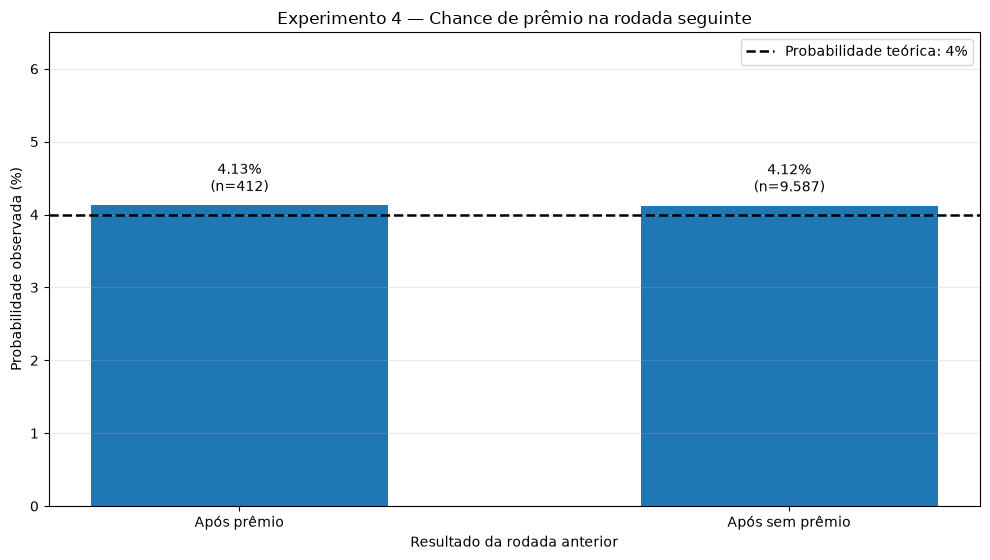

Gráfico salvo em: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\graficos\notebooks\e4_probabilidades_condicionais.png


In [5]:
fig, ax = plt.subplots(figsize=(10, 5.7))

taxas = (df["probabilidade_calculada"] * 100).to_numpy()
rotulos = df["condicao_curta"].tolist()
barra = ax.bar(rotulos, np.nan_to_num(taxas), width=0.54)

referencia_pct = 4.0
ax.axhline(
    referencia_pct, linestyle="--", linewidth=1.8, color="black",
    label="Probabilidade teórica: 4%"
)

for retangulo, taxa, total in zip(barra, taxas, df["total_pares"]):
    rotulo = "Não estimável" if np.isnan(taxa) else f"{taxa:.2f}%"
    ax.annotate(
        f"{rotulo}\n(n={total:,})".replace(",", "."),
        (retangulo.get_x() + retangulo.get_width() / 2, retangulo.get_height()),
        ha="center", va="bottom", fontsize=10, xytext=(0, 7),
        textcoords="offset points"
    )

ax.set(
    title="Experimento 4 — Chance de prêmio na rodada seguinte",
    xlabel="Resultado da rodada anterior",
    ylabel="Probabilidade observada (%)",
)
ax.set_ylim(0, max(6.5, np.nanmax(taxas) + 1.5) if np.isfinite(taxas).any() else 6.5)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()

saida_taxas = pasta_graficos / "e4_probabilidades_condicionais.png"
fig.savefig(saida_taxas, dpi=200, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", saida_taxas)

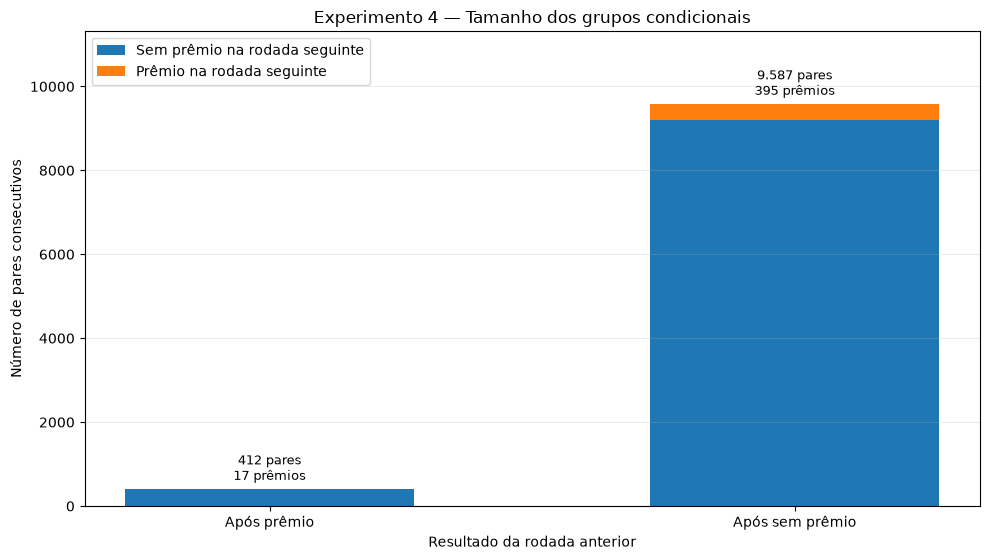

Gráfico salvo em: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\graficos\notebooks\e4_contagens_pares_condicionais.png


In [6]:
fig, ax = plt.subplots(figsize=(10, 5.7))

x = np.arange(len(df))
com_premio = df["premios_seguintes"].to_numpy()
sem_premio = (
    df["total_pares"] - df["premios_seguintes"]
).to_numpy()

ax.bar(x, sem_premio, width=0.55, label="Sem prêmio na rodada seguinte")
ax.bar(x, com_premio, width=0.55, bottom=sem_premio,
       label="Prêmio na rodada seguinte")

for posicao, total, premios in zip(x, df["total_pares"], com_premio):
    ax.text(posicao, total + 110, f"{total:,} pares\n{premios} prêmios".replace(",", "."),
            ha="center", va="bottom", fontsize=9)

ax.set(
    title="Experimento 4 — Tamanho dos grupos condicionais",
    xlabel="Resultado da rodada anterior",
    ylabel="Número de pares consecutivos",
)
ax.set_xticks(x, df["condicao_curta"])
ax.set_ylim(0, max(df["total_pares"].max() * 1.18, 1))
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()

saida_pares = pasta_graficos / "e4_contagens_pares_condicionais.png"
fig.savefig(saida_pares, dpi=200, bbox_inches="tight")
plt.show()
print("Gráfico salvo em:", saida_pares)

In [7]:
for linha in df.itertuples(index=False):
    if linha.total_pares == 0:
        print(f"{linha.condicao_curta}: proporção não estimável (nenhum par).")
        continue

    p = linha.probabilidade_calculada * 100
    diferenca_pp = (linha.probabilidade_calculada - 0.04) * 100
    print(
        f"{linha.condicao_curta}: {linha.premios_seguintes}/{linha.total_pares} "
        f"= {p:.4f}% (diferença da teoria: {diferenca_pp:+.4f} p.p.)"
    )

print(f"Total de pares: {df['total_pares'].sum():,}".replace(",", "."))
print("Referência teórica após prêmio e após perda: 4% em ambos os casos.")
print("Conclusão: os dados descrevem a simulação; a independência decorre da regra de sorteio.")

Após prêmio: 17/412 = 4.1262% (diferença da teoria: +0.1262 p.p.)
Após sem prêmio: 395/9587 = 4.1202% (diferença da teoria: +0.1202 p.p.)
Total de pares: 9.999
Referência teórica após prêmio e após perda: 4% em ambos os casos.
Conclusão: os dados descrevem a simulação; a independência decorre da regra de sorteio.
